# 03 · Distributions of the key variables

One variable at a time: how are counts, densities and shares distributed, how skewed are they, what transform symmetrises them, and how many outliers are there. Reads `eda_outputs/base_table.parquet`.

In [1]:
import warnings; warnings.filterwarnings("ignore")
import pathlib
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy import stats

ROOT = next(p for p in [pathlib.Path.cwd(), *pathlib.Path.cwd().parents] if (p / "data").exists())
DATA, OUT, ANALYSIS = ROOT / "data", ROOT / "eda_outputs", ROOT / "analysis_outputs"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": .25, "axes.titlesize": 11, "axes.labelsize": 9})
REG = ["maricopa-az", "northern-ca", "eastern-ok", "south-central-tx", "eastern-wa"]
NAME = {"maricopa-az": "Maricopa AZ", "northern-ca": "Northern CA", "eastern-ok": "Eastern OK", "south-central-tx": "S-C Texas", "eastern-wa": "Eastern WA"}
COL = dict(zip(REG, ["#e07b39", "#c0504d", "#6a9e4f", "#3b6fb6", "#8e6bbf"]))
df = pd.read_parquet(OUT / "base_table.parquet")

def box_by_region(ax, col, log=False, title="", ylabel=None, data=None):
    d = df if data is None else data
    vals = [d.loc[d.region == r, col].dropna() for r in REG]
    if log: vals = [np.log10(v[v > 0]) for v in vals]
    bp = ax.boxplot(vals, patch_artist=True, medianprops=dict(color="k"), flierprops=dict(marker=".", markersize=2, alpha=.3))
    for patch, r in zip(bp["boxes"], REG): patch.set_facecolor(COL[r]); patch.set_alpha(.75)
    ax.set_xticks(range(1, 6)); ax.set_xticklabels([f"{NAME[r]}\nn={len(v):,}" for r, v in zip(REG, vals)], fontsize=7.5)
    ax.set_title(title); ax.set_ylabel(ylabel or (("log10 " if log else "") + col))

def n_outliers(s):
    s = s.dropna(); q1, q3 = s.quantile([.25, .75]); k = 1.5 * (q3 - q1)
    return int(((s < q1 - k) | (s > q3 + k)).sum())

def heat(ax, M, fmt="{:.2f}", cmap="RdBu_r", vmin=-1, vmax=1, fs=7, rot=60):
    im = ax.imshow(M.values, cmap=cmap, vmin=vmin, vmax=vmax, aspect="auto"); ax.grid(False)
    ax.set_xticks(range(M.shape[1])); ax.set_xticklabels(M.columns, rotation=rot, ha="right", fontsize=8)
    ax.set_yticks(range(M.shape[0])); ax.set_yticklabels(M.index, fontsize=8)
    for i in range(M.shape[0]):
        for j in range(M.shape[1]):
            v = M.values[i, j]; ax.text(j, i, fmt.format(v), ha="center", va="center", fontsize=fs, color="k" if abs(v - (vmin + vmax) / 2) < (vmax - vmin) * .35 else "w")
    return im

## 1. Summary statistics of the key variables

                         n     mean   median       sd   min        max   skew  ex. kurtosis  % zero
variable                                                                                           
buildings             9794  1957.30  1724.00  1238.11  0.00   16723.00   1.68          6.67    0.02
road km               9794   109.22    37.25   231.86  0.00    4696.88   6.36         64.45    0.02
POIs                  9794   204.32   142.00   231.18  0.00    5236.00   5.68         66.62    0.02
population            9794  4127.77  3901.00  1902.06  0.00   30199.00   1.68         10.57    0.28
housing units         9794  1746.68  1645.00   807.70  0.00   13827.00   1.94         14.91    0.84
land km2              9794   108.86     3.97   428.55  0.00    8892.51   8.54        102.01    0.02
buildings / km2       9792   404.73   360.13   336.50  0.01    2281.77   0.77          0.34    0.00
road km / km2         9792     8.15     8.74     4.95  0.00      30.87   0.10         -0.73    0.00


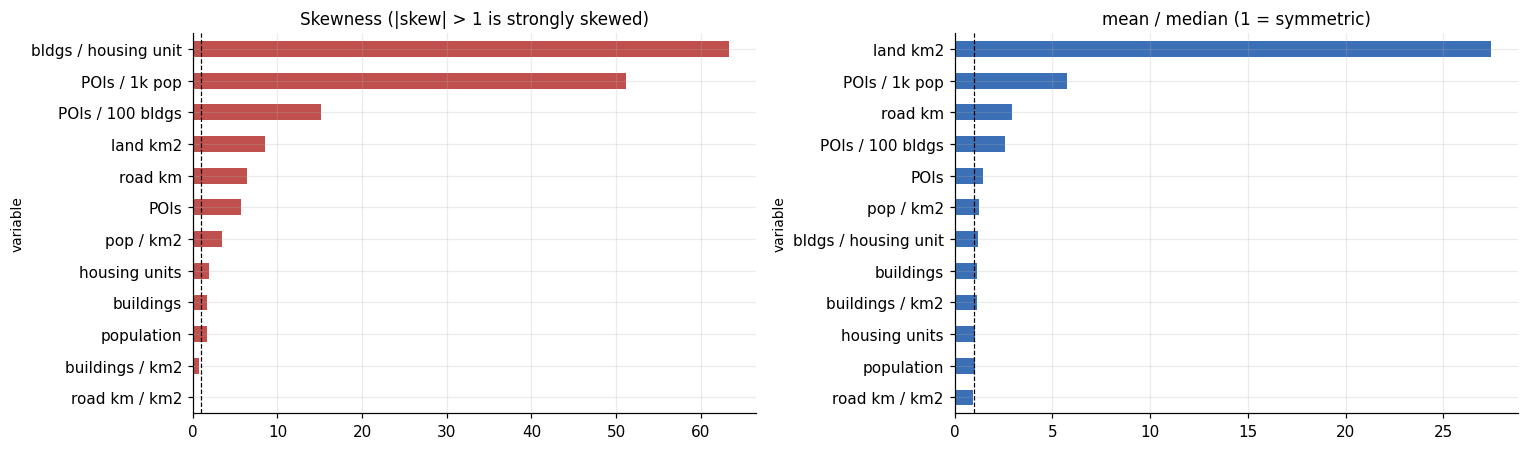

In [2]:
V = {"bldg_n": "buildings", "road_km_all": "road km", "poi_n": "POIs", "pop_total": "population", "housing_units": "housing units", "land_km2": "land km2",
     "bldg_per_km2": "buildings / km2", "road_km_per_km2": "road km / km2", "poi_per_100_bldg": "POIs / 100 bldgs", "poi_per_1k_pop": "POIs / 1k pop", "bldg_per_hu": "bldgs / housing unit", "pop_density": "pop / km2"}
rows = []
for c, nm in V.items():
    x = df[c].dropna(); rows.append((nm, len(x), x.mean(), x.median(), x.std(), x.min(), x.max(), stats.skew(x), stats.kurtosis(x), (x == 0).mean() * 100))
S = pd.DataFrame(rows, columns=["variable", "n", "mean", "median", "sd", "min", "max", "skew", "ex. kurtosis", "% zero"]).set_index("variable"); print(S.round(2).to_string())
fig, ax = plt.subplots(1, 2, figsize=(14, 4.2)); S.skew_ = S["skew"]; S["skew"].sort_values().plot.barh(ax=ax[0], color="#c0504d"); ax[0].axvline(1, color="k", ls="--", lw=.8); ax[0].set_title("Skewness (|skew| > 1 is strongly skewed)")
(S["mean"] / S["median"]).sort_values().plot.barh(ax=ax[1], color="#3b6fb6"); ax[1].axvline(1, color="k", ls="--", lw=.8); ax[1].set_title("mean / median (1 = symmetric)")
plt.tight_layout(); plt.show()

**Takeaway:** population per tract is nearly uniform in size (median 3,901, sd 1,902), because tracts are drawn to hold about 4,000 people, while land area is extreme (median 4 km2, mean 109, max 8,893). Buildings and population are mildly skewed (1.7), road km (6.4), POIs (5.7) and land (8.5) strongly. Roads per km2 is already symmetric (skew 0.10). Two ratios are dominated by tiny denominators: POIs per 1,000 residents reaches 356,000 and buildings per housing unit reaches 212, so those need capping or transforming.

## 2. Raw versus log scale

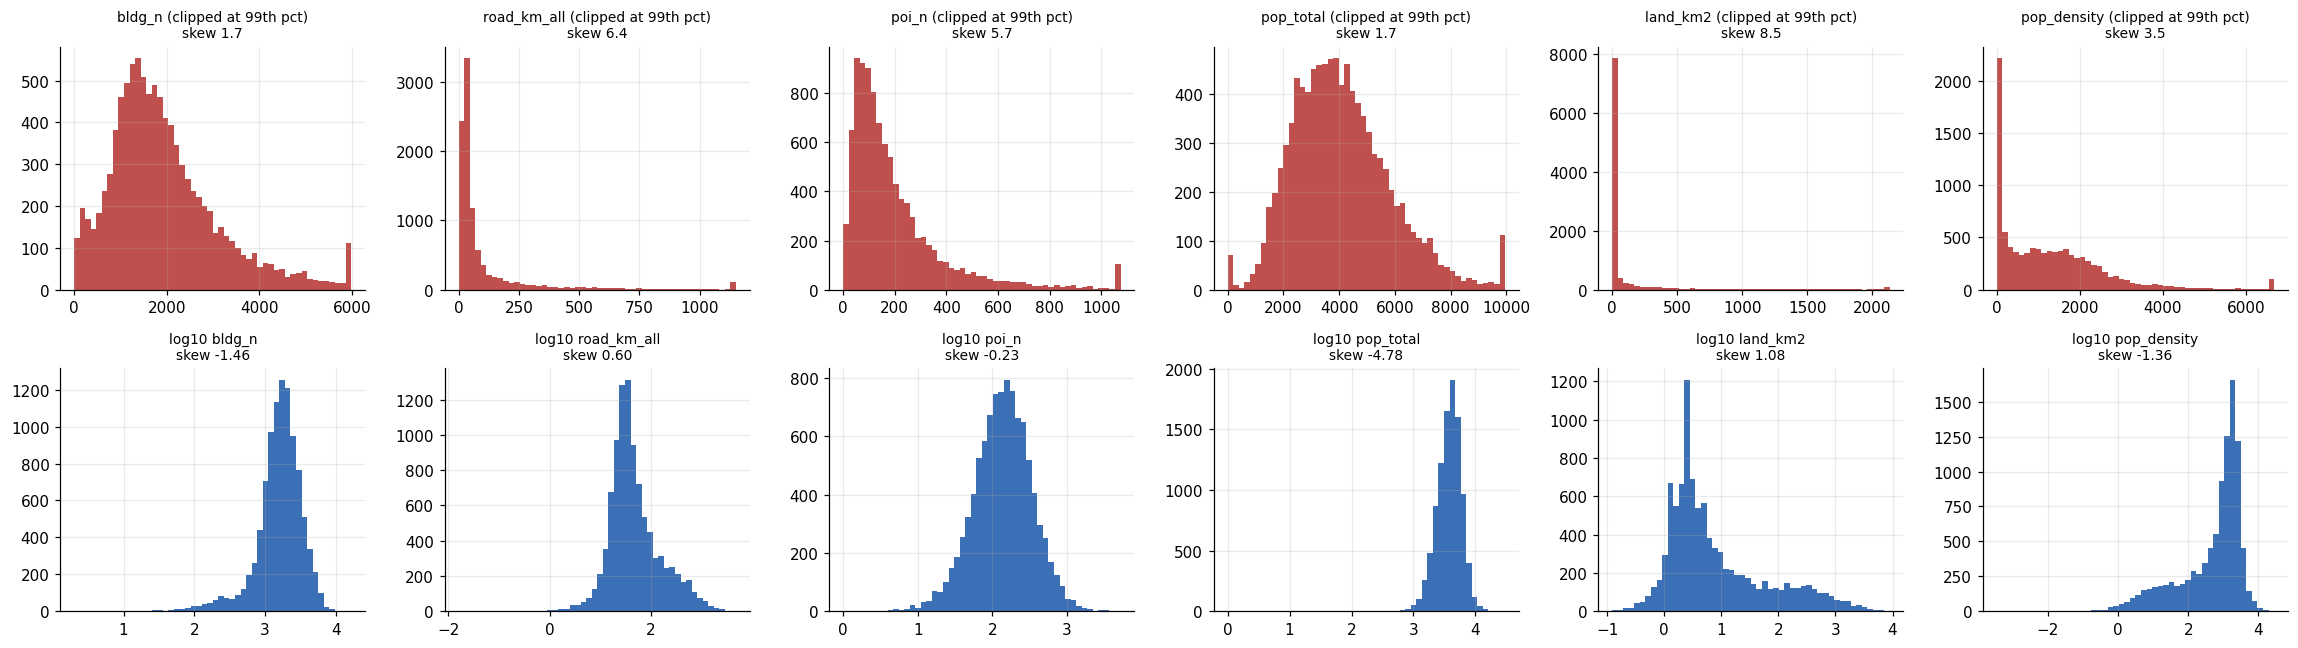

In [3]:
cols = ["bldg_n", "road_km_all", "poi_n", "pop_total", "land_km2", "pop_density"]
fig, ax = plt.subplots(2, 6, figsize=(21, 6))
for j, c in enumerate(cols):
    x = df[c].dropna(); ax[0, j].hist(x.clip(upper=x.quantile(.99)), bins=50, color="#c0504d"); ax[0, j].set_title(f"{c} (clipped at 99th pct)\nskew {stats.skew(x):.1f}", fontsize=9)
    lx = np.log10(x[x > 0]); ax[1, j].hist(lx, bins=50, color="#3b6fb6"); ax[1, j].set_title(f"log10 {c}\nskew {stats.skew(lx):.2f}", fontsize=9)
plt.tight_layout(); plt.show()

**Takeaway:** the log scale turns the long right tails into bell shapes for land area, road length and POIs. But `log1p` over-corrects buildings (skew -1.6) and population (-6.1, driven by a few near-empty tracts), so one transform does not suit every variable.

## 3. Which transform makes each variable most symmetric?

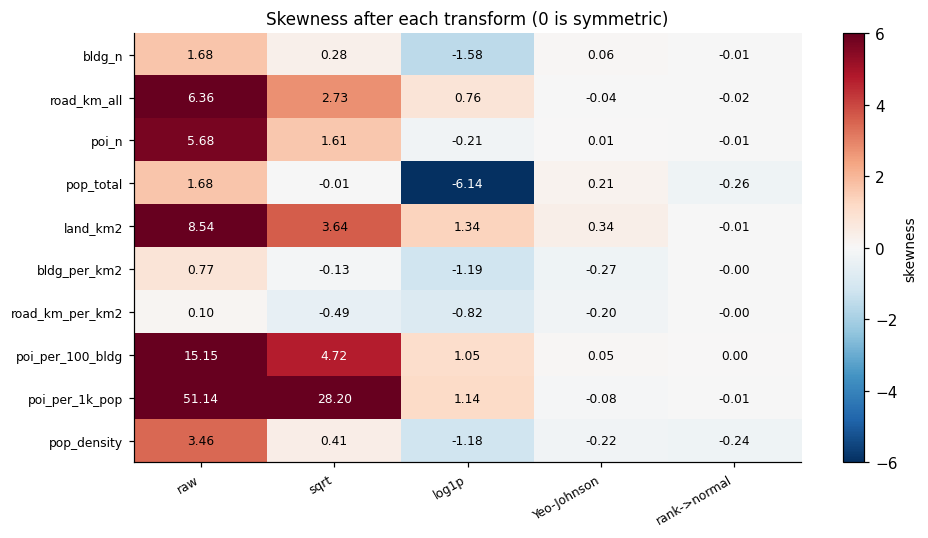

                    raw   sqrt  log1p  Yeo-Johnson  rank->normal
bldg_n             1.68   0.28  -1.58         0.06         -0.01
road_km_all        6.36   2.73   0.76        -0.04         -0.02
poi_n              5.68   1.61  -0.21         0.01         -0.01
pop_total          1.68  -0.01  -6.14         0.21         -0.26
land_km2           8.54   3.64   1.34         0.34         -0.01
bldg_per_km2       0.77  -0.13  -1.19        -0.27         -0.00
road_km_per_km2    0.10  -0.49  -0.82        -0.20         -0.00
poi_per_100_bldg  15.15   4.72   1.05         0.05          0.00
poi_per_1k_pop    51.14  28.20   1.14        -0.08         -0.01
pop_density        3.46   0.41  -1.18        -0.22         -0.24

best by |skew|: {'bldg_n': 'rank->normal', 'road_km_all': 'rank->normal', 'poi_n': 'Yeo-Johnson', 'pop_total': 'sqrt', 'land_km2': 'rank->normal', 'bldg_per_km2': 'rank->normal', 'road_km_per_km2': 'rank->normal', 'poi_per_100_bldg': 'rank->normal', 'poi_per_1k_pop': 'rank->normal', 

In [4]:
from sklearn.preprocessing import PowerTransformer, QuantileTransformer
cols = ["bldg_n", "road_km_all", "poi_n", "pop_total", "land_km2", "bldg_per_km2", "road_km_per_km2", "poi_per_100_bldg", "poi_per_1k_pop", "pop_density"]
rows = {}
for c in cols:
    x = df[c].dropna().values.reshape(-1, 1); rows[c] = {"raw": stats.skew(x.ravel()), "sqrt": stats.skew(np.sqrt(x.ravel())), "log1p": stats.skew(np.log1p(x.ravel())),
        "Yeo-Johnson": stats.skew(PowerTransformer("yeo-johnson").fit_transform(x).ravel()), "rank->normal": stats.skew(QuantileTransformer(output_distribution="normal", random_state=0).fit_transform(x).ravel())}
M = pd.DataFrame(rows).T; fig, ax = plt.subplots(figsize=(9, 5)); plt.colorbar(heat(ax, M, vmin=-6, vmax=6, fs=8, rot=30), ax=ax, label="skewness"); ax.set_title("Skewness after each transform (0 is symmetric)")
plt.tight_layout(); plt.show(); print(M.round(2).to_string()); print("\nbest by |skew|:", M.abs().idxmin(axis=1).to_dict())

**Takeaway:** a rank-to-normal transform brings every variable to skew about 0, and Yeo-Johnson keeps all of them within +-0.35. Square root is best for population (-0.01) and good for buildings (0.28). For linear models use Yeo-Johnson or a variable-specific choice; tree models do not need any of this.

## 4. Outliers: raw versus log

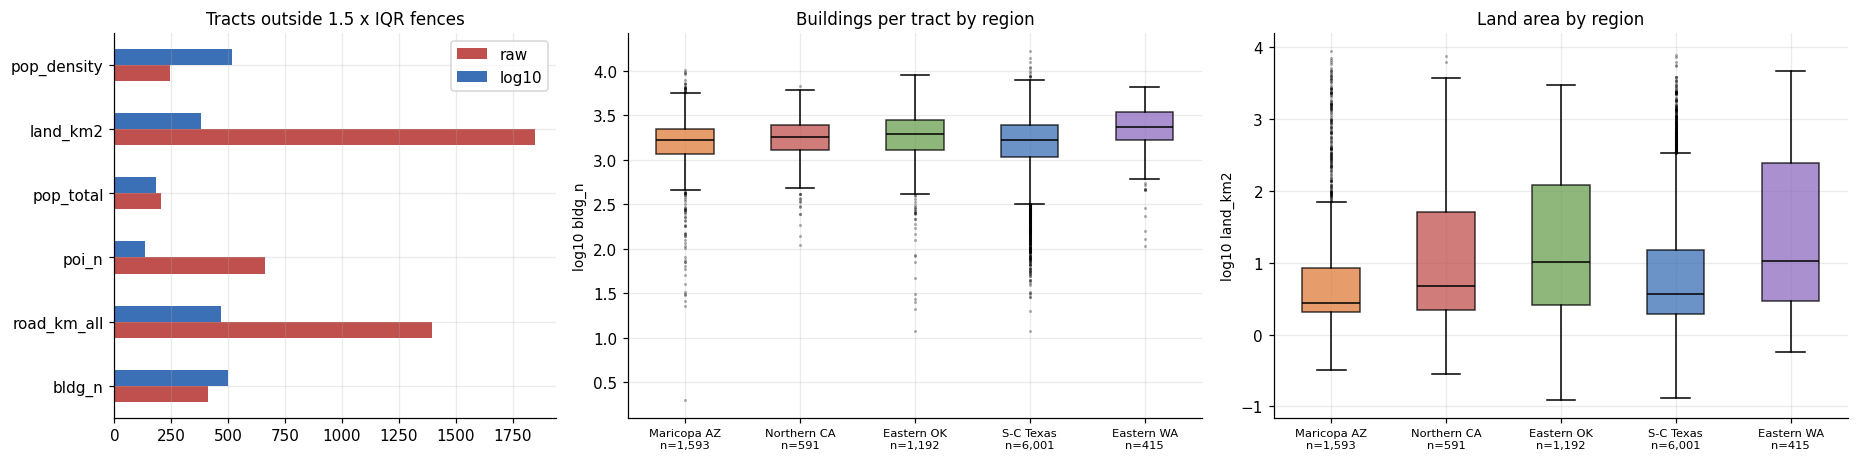

              raw  log10
bldg_n        413    498
road_km_all  1395    471
poi_n         663    137
pop_total     207    185
land_km2     1849    381
pop_density   244    516

largest 5 tracts by land km2:
      GEOID           region  land_km2  pop_total  bldg_n
35023970000      maricopa-az    8893.0       1912  2965.0
48465950802 south-central-tx    7706.0       1933  5279.0
06035040100      northern-ca    7530.0       1627  3072.0
48105950100 south-central-tx    7271.0       3098  4385.0
04005001500      maricopa-az    6917.0       3528  9135.0


In [5]:
cols = ["bldg_n", "road_km_all", "poi_n", "pop_total", "land_km2", "pop_density"]
O = pd.DataFrame({"raw": {c: n_outliers(df[c]) for c in cols}, "log10": {c: n_outliers(np.log10(df[c][df[c] > 0])) for c in cols}})
fig, ax = plt.subplots(1, 3, figsize=(17, 4.3), gridspec_kw={"width_ratios": [1, 1.3, 1.3]})
O.plot.barh(ax=ax[0], color=["#c0504d", "#3b6fb6"]); ax[0].set_title("Tracts outside 1.5 x IQR fences")
box_by_region(ax[1], "bldg_n", log=True, title="Buildings per tract by region"); box_by_region(ax[2], "land_km2", log=True, title="Land area by region")
plt.tight_layout(); plt.show(); print(O.to_string()); print("\nlargest 5 tracts by land km2:"); print(df.nlargest(5, "land_km2")[["GEOID", "region", "land_km2", "pop_total", "bldg_n"]].round(0).to_string(index=False))

**Takeaway:** taking logs cuts IQR outliers a lot for road length (1,395 to 471), POIs (663 to 137) and land area (1,849 to 381), but raises them for buildings (413 to 498) and density (244 to 516) because the low tail is now flagged. The largest tracts are real: rural tracts of up to 8,893 km2 holding only 1,600-3,500 people. They should be kept, not dropped.

## 5. Bounded variables: shares and percentages

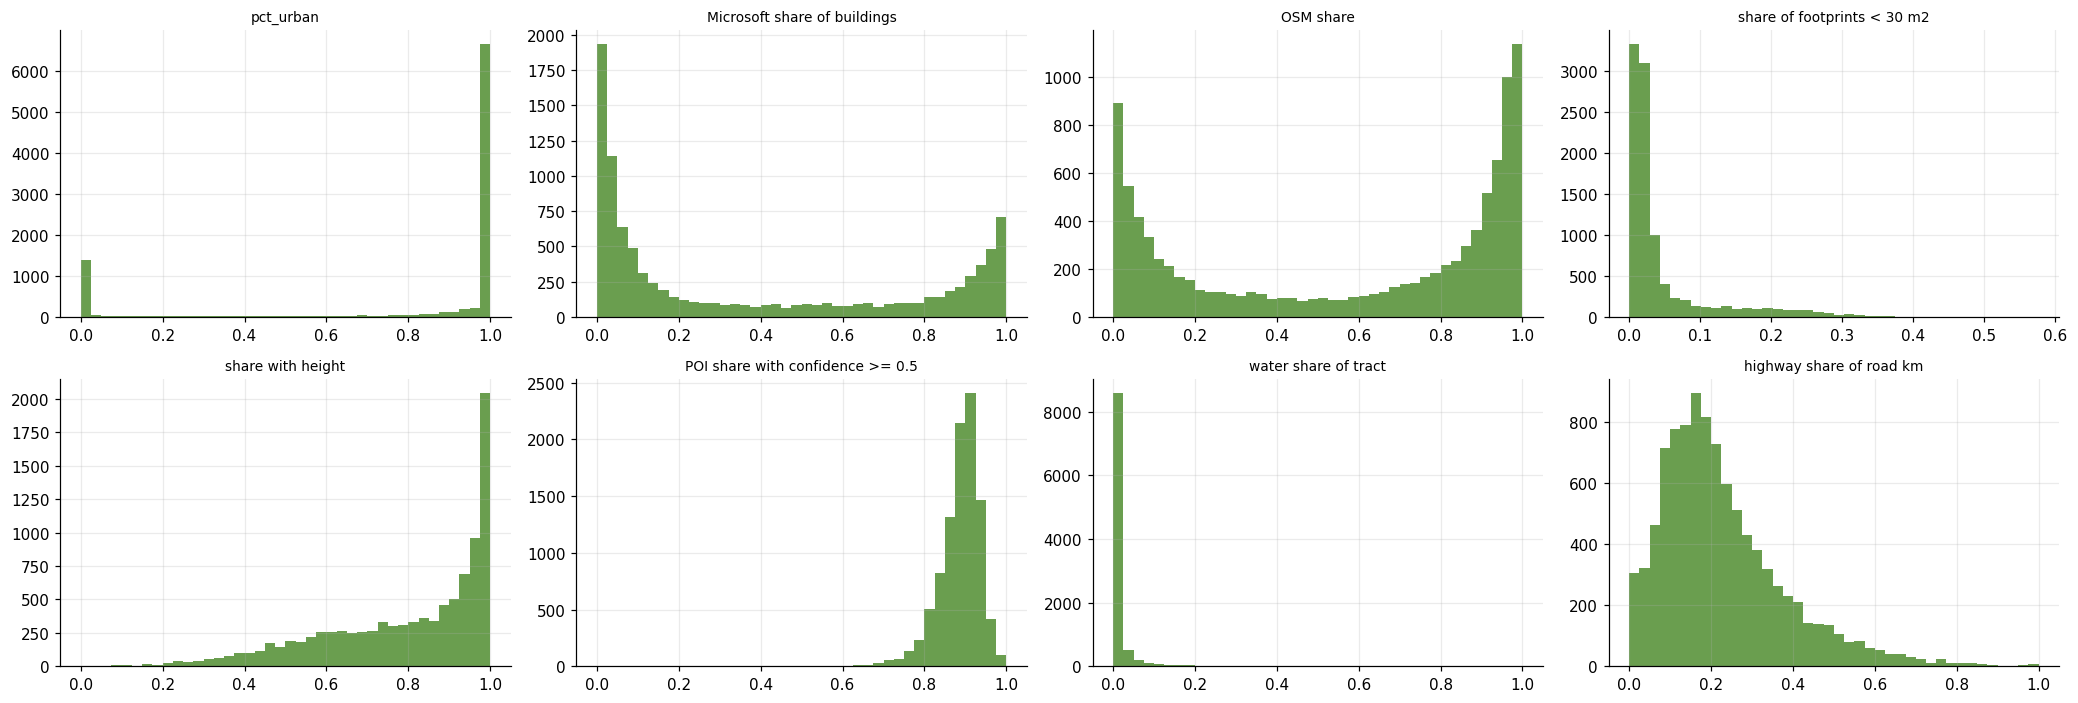

                        variable  median  % exactly 0  % exactly 1  skew
                       pct_urban    1.00        13.42        62.75 -1.54
    Microsoft share of buildings    0.17         0.50         0.18  0.52
                       OSM share    0.73         0.26         0.20 -0.33
     share of footprints < 30 m2    0.02         1.23         0.00  2.42
               share with height    0.86         0.02         0.68 -0.99
POI share with confidence >= 0.5    0.89         0.01         0.57 -4.09
            water share of tract    0.00        45.69         0.02  7.13
        highway share of road km    0.19         1.38         0.02  1.29


In [6]:
S2 = {"pct_urban": "pct_urban", "share_msft": "Microsoft share of buildings", "share_osm": "OSM share", "tiny_share": "share of footprints < 30 m2", "height_share": "share with height", "conf05_share": "POI share with confidence >= 0.5", "water_share": "water share of tract", "hwy_share_of_road_km": "highway share of road km"}
fig, ax = plt.subplots(2, 4, figsize=(19, 6.5)); rows = []
for a, (c, nm) in zip(ax.ravel(), S2.items()):
    x = df[c].dropna(); a.hist(x, bins=40, color="#6a9e4f"); a.set_title(nm, fontsize=9); rows.append((nm, x.median(), (x == 0).mean() * 100, (x == 1).mean() * 100, stats.skew(x)))
plt.tight_layout(); plt.show(); print(pd.DataFrame(rows, columns=["variable", "median", "% exactly 0", "% exactly 1", "skew"]).round(2).to_string(index=False))

**Takeaway:** the shares are far from normal. `pct_urban` is at exactly 1 for 63% of tracts and exactly 0 for 13% (76% at the extremes), and 46% of tracts have zero water. Height data and POI confidence are near-complete: the median share with height is 0.86 (68% of tracts at exactly 1), and 57% of tracts have every POI at confidence 0.5 or more. The Microsoft share has median 0.17 and the OSM share 0.73, so OSM is the main building source for the typical tract.